# 07 · Exogenous Feature Importance — the central result

**Objective.** Answer the research question: **which external feature most improves CNN
`SWC_20` forecasting, beyond historical soil moisture?** We rank configs B–F by %RMSE
change vs the SWC-only baseline (A), aggregated over 5 station-years × 5 horizons = 25
cells per config.

**Provenance & reproducibility**

- **Results shown here:** ⬇ **derived from the Nov-17 results.** `results/feature_importance_ranking.csv` is computed in this refactor by aggregating `results/nov17_results.csv` (% RMSE change vs config A for every station-year×horizon cell). Figures from `figures/`.
- **Experimental setup:** Configs B–F vs baseline A; 25 cells each; metric = mean/median %RMSE change vs A, plus how many of the 25 cells each config actually improves.
- **Implementation:** Aggregation of `run_fold` outputs (notebook 03); ranking + figures in `notebooks/make_figures.py`; feature definitions in `src.config.FEATURE_GROUPS`.
- **Original code:** the 150 production CNN runs and the HP sweep were generated by the original monolithic notebook, preserved at `archive/cnn_experiments_original_monolithic.ipynb` (run live on Google Colab GPU, 2026-11-17); the notebooks here are the refactored, `src/`-based version of that same pipeline.
- **Reproduce:** Re-run notebook 03 to regenerate `nov17_results.csv` on GPU, then re-run this notebook (CPU) to recompute the ranking and figures.

In [1]:
# --- project setup: portable across local / Google Drive / fresh Colab ---
import os, sys

def find_project_root(marker="src"):
    # 1) walk up from the current directory (local checkout or Drive upload)
    p = os.path.abspath(os.getcwd())
    while p != os.path.dirname(p):
        if os.path.isdir(os.path.join(p, marker)):
            return p
        p = os.path.dirname(p)
    # 2) common Colab upload locations
    for c in ("/content/soil_moisture_research",
              "/content/drive/MyDrive/soil_moisture_research"):
        if os.path.isdir(os.path.join(c, marker)):
            return c
    raise FileNotFoundError(
        "Could not find the project root (a folder containing 'src/').\n"
        "Upload the whole soil_moisture_research/ folder to Drive/Colab and "
        "open this notebook from inside notebooks/.")

ROOT = find_project_root()
sys.path.insert(0, ROOT)
os.chdir(ROOT)
print("project root set ->", os.path.basename(ROOT))  # portable: no absolute path

project root set -> soil_moisture_research


In [2]:
import pandas as pd
rank = pd.read_csv('results/feature_importance_ranking.csv')
rank.round(2)

,config,n,mean_vs_swc,median_vs_swc,std_vs_swc,n_better_swc,pct_better,best_cell,worst_cell,mean_vs_persist
0,E: + air temperature,25,-1.42,-1.09,2.05,8,32.0,1.80,-6.19,-0.99
1,B: + existing rain,25,-1.53,-0.88,4.70,8,32.0,4.15,-17.35,-1.09
2,D: + cumulative rain,25,-1.70,-0.94,7.11,8,32.0,13.42,-19.79,-1.21
3,C: + lagged rain,25,-2.91,-1.53,6.17,10,40.0,3.00,-24.05,-2.47
4,F: combined met,25,-3.86,-2.48,8.77,9,36.0,3.64,-39.82,-3.39


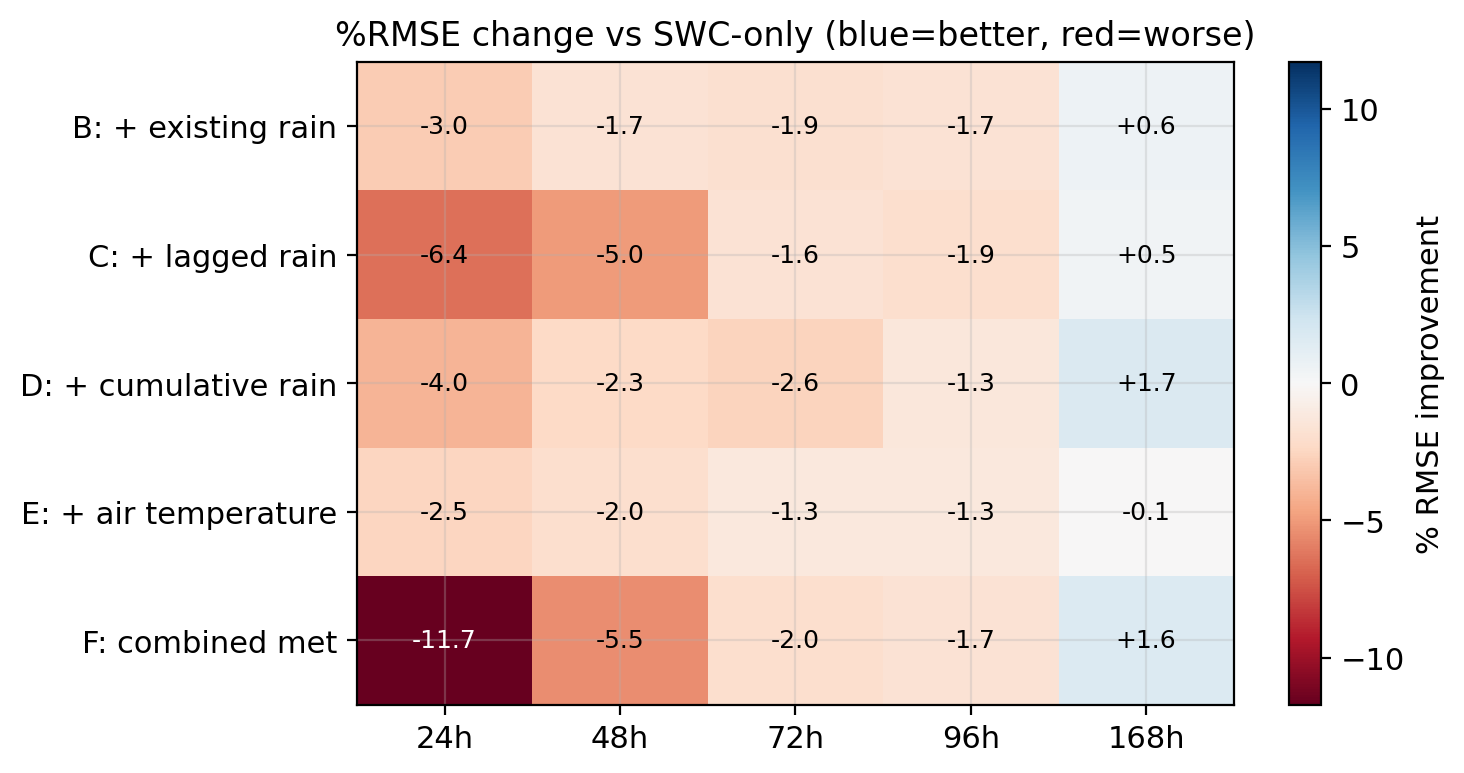

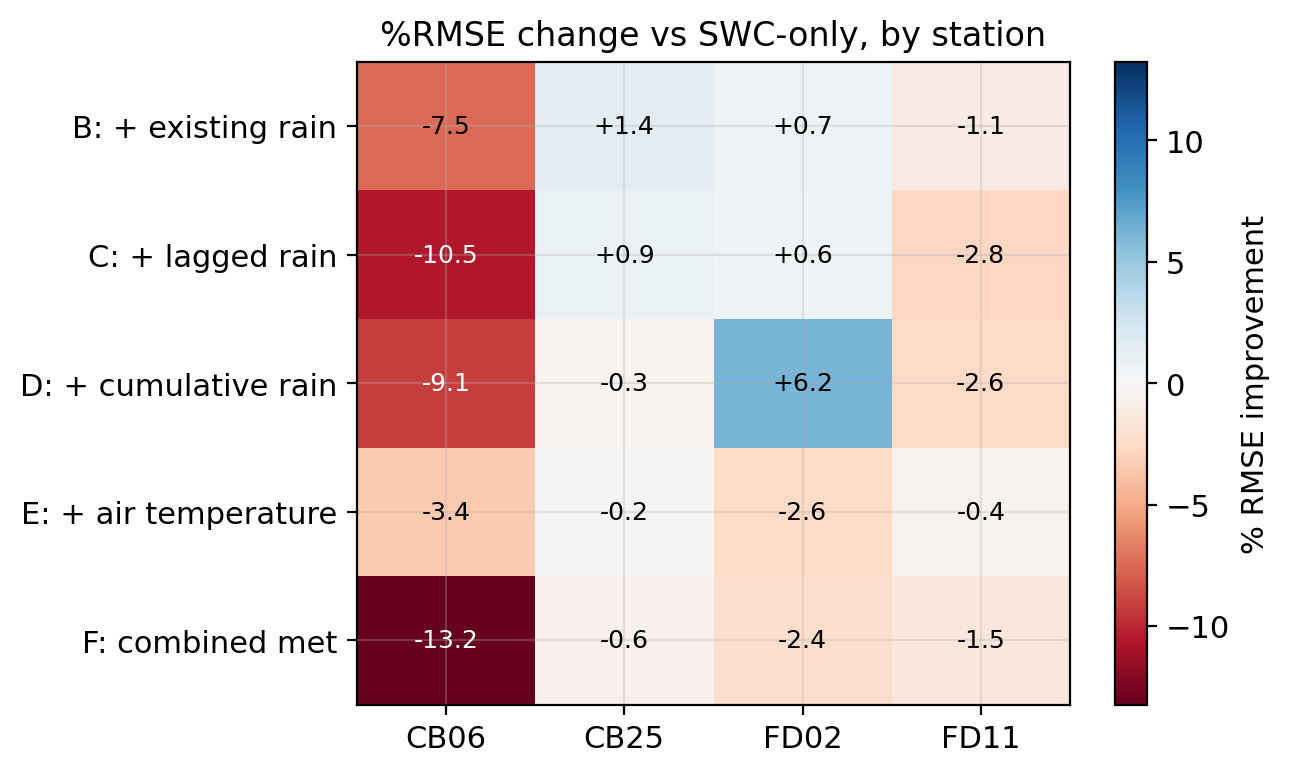

In [3]:
from IPython.display import Image, display
display(Image('figures/fig_feature_importance_heatmap.png'))
display(Image('figures/fig_feature_by_station.png'))

## Interpreting "feature importance" — three questions that must not be conflated

**1. Smallest average RMSE degradation — a "least-harmful" ordering, NOT importance.**
By mean %RMSE change vs SWC-only across all 25 cells:
E air-temperature (−1.42%) > B existing-rain (−1.53%) > D cumulative-rain (−1.70%) >
C lagged-rain (−2.91%) > F combined-met (−3.86%). **Every value is negative** — on average
*adding any exogenous feature makes the forecast worse than SWC-only*. This ranks which
addition does the **least damage**; it is not evidence that any feature is "important."

**2. Features that help at particular stations.** The effect is station-dependent.
Cumulative rainfall (D) is the only configuration with a clearly positive *local* effect,
at the **driest** station **FD02** (best cell +13.4% RMSE reduction). Physically sensible —
where soil is dry, rain drives most of the moisture change — but a *conditional* effect,
not a global one.

**3. What can genuinely be called "important" (controlled ablation).** *Nothing, yet.*
This study uses a **forward-addition** design (A = SWC-only, then A + one feature group).
That confounds "is this feature informative?" with "does adding an input channel to a
~2k-parameter CNN inject more estimation noise than signal?" — and for a model this small on
a strong-persistence target, the noise usually wins.

### Why we do NOT claim a definitive importance ranking
Because **every** configuration underperforms SWC-only on average, the data do **not**
support a claim such as "precipitation is the most important exogenous feature." The
strongest *supported* statements are: (i) exogenous features do not improve this CNN on
average; (ii) air temperature and single-step rain are the least harmful additions;
(iii) cumulative rain helps specifically at the driest station (FD02).

### What a stronger conclusion would require
A **leave-one-group-out (LOGO)** ablation — start from the full feature set and remove one
group at a time — isolates each feature's *marginal* contribution far better than adding it
to a bare baseline, because the receptive field and channel count stay comparable. Combined
with **multiple seeds** (these are single-seed runs; the `std_vs_swc` column shows 2–9%
between-cell spread, larger than the mean effects), that would let us attach significance to
any ranking. Until then, the per-feature means here are **descriptive, not a validated
importance ranking.**